Input: [0.25 0.5  0.75 1.  ]
Target: [0.5  0.75 1.   1.25]
Weights initialized
Actual: [2.5  3.75 5.   6.25]
Predicted: [2.51 3.72 5.06 6.22]
Final Loss: 0.000062


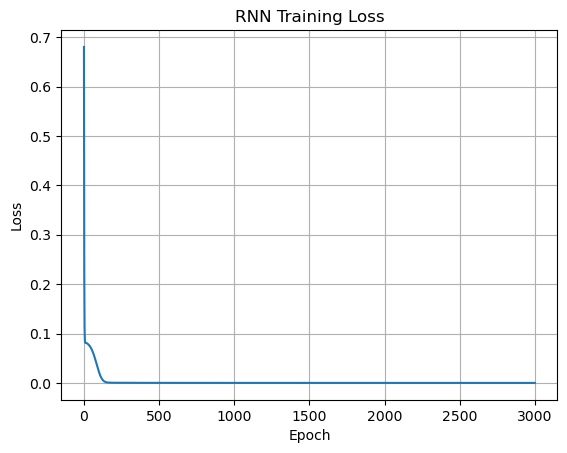

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Input and target data
x = np.array([1, 2, 3, 4]) / 4
target = np.array([2, 3, 4, 5]) / 4

print("Input:", x)
print("Target:", target)

# Initialize weights and biases
np.random.seed(42)

wx, wh, wy = np.random.randn(3) * 0.1
bh, by = 0.0, 0.0

print("Weights initialized")

# Training parameters
lr = 0.08
epochs = 3000
loss_history = []

# Train the RNN
for epoch in range(epochs):
    h = 0
    total_loss = 0

    for value, actual in zip(x, target):
        old_h = h

        # RNN forward pass
        h = np.tanh(wx * value + wh * old_h + bh)
        prediction = wy * h + by

        # Calculate error
        error = prediction - actual
        total_loss += error ** 2

        # Update weights
        d = error * wy * (1 - h ** 2)

        wy -= lr * error * h
        by -= lr * error
        wx -= lr * d * value
        wh -= lr * d * old_h
        bh -= lr * d

    loss_history.append(total_loss / len(x))

# Test the RNN
h = 0
predictions = []

for value in x:
    h = np.tanh(wx * value + wh * h + bh)
    y = wy * h + by
    predictions.append(y)

predictions = np.array(predictions)

print("Actual:", target * 5)
print("Predicted:", np.round(predictions * 5, 2))
print("Final Loss:", format(loss_history[-1], ".6f"))

# Plot training loss
plt.plot(loss_history)
plt.title("RNN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid()
plt.show()